# Water bridges comparative analysis - WT vs T419R vs S466R

In [2]:
import pandas as pd
from scipy.stats import mannwhitneyu
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Note: check the timeseries plots computed through snakemake to compare the average number of contacts below the threshold per timeframe and over the analyzed period. This notebook focuses on the analysis of the pair contacts.

## Load data

In [3]:
wt_dfs = []
for rep in range(1, 4):
    wb_df = pd.read_csv(f'../../data/1bf5/wt/rep{rep}/analysis/002_hbonds/waterbridges.csv')
    wt_dfs.append(wb_df)

T419R_dfs = []
for rep in range(1, 4):
    wb_df = pd.read_csv(f'../../data/1bf5/T419R/rep{rep}/analysis/002_hbonds/waterbridges.csv')
    T419R_dfs.append(wb_df)

S466R_dfs = []
for rep in range(1, 4):
    wb_df = pd.read_csv(f'../../data/1bf5/S466R/rep{rep}/analysis/002_hbonds/waterbridges.csv')
    S466R_dfs.append(wb_df)

In [4]:
len(wt_dfs)

3

In [5]:
len(T419R_dfs)

3

In [6]:
len(S466R_dfs)

3

Add adjusted residue numbers.

In [7]:
for df in (wt_dfs + T419R_dfs + S466R_dfs):
    df["sele1_resid_adj"] = np.where(
        (df["sele1_resnm"].str.match(r'^[A-Za-z]{3}$')) & (df["sele1_resnm"] != "WAT"),
        df["sele1_resid"] + 135,
        df["sele1_resid"]
    )
    df["sele2_resid_adj"] = np.where(
        (df["sele2_resnm"].str.match(r'^[A-Za-z]{3}$')) & (df["sele2_resnm"] != "WAT"),
        df["sele2_resid"] + 135,
        df["sele2_resid"]
    )

In [8]:
wt_dfs[1].head()

,time,sele1_index,sele2_index,sele1_resnm,sele1_resid,sele1_atom,sele2_resnm,sele2_resid,sele2_atom,distance,angle,sele1_resid_adj,sele2_resid_adj
0,100900.0,14154,417321,ARG,283,HH21,WAT,99835,H2,2.407864,120.306876,418,99835
1,100900.0,417321,19732,WAT,99835,H2,DA,6,H2,2.974124,139.508148,99835,6
2,101200.0,14155,152887,ARG,283,HH22,WAT,33727,O,3.146806,148.007760,418,33727
3,101200.0,152889,19732,WAT,33727,H2,DA,6,H2,3.218076,123.058982,33727,6
4,102000.0,14148,347531,ARG,283,HE,WAT,82388,O,2.109737,149.223424,418,82388


## Filter direct hydrogen bonds and aggregate data

The identified "water bridges" include bonds that are in fact direct hydrogen bonds between the protein and DNA. We will filter these out to focus on water bridges.

In [9]:
# Aggregate hbond counts for each unique hbond across replicates or methods
def aggregate_hbonds(df_list, label):
    combined = pd.concat(df_list)
    combined= combined[(combined["sele1_resnm"] == "WAT") | (combined["sele2_resnm"] == "WAT")]
    agg_df = combined.groupby(['sele1_index', 'sele2_index', 'sele1_resid_adj', 
                               'sele2_resid_adj', 'sele1_resnm', 'sele2_resnm']).size().reset_index(name='count')

    agg_df['group'] = label
    return combined, agg_df

In [10]:

wt_combined, wt_agg = aggregate_hbonds(wt_dfs, 'wt')
T419R_combined, T419R_agg = aggregate_hbonds(T419R_dfs, 'T419R')
S466R_combined, S466R_agg = aggregate_hbonds(S466R_dfs, 'S466R')

## Filter out one-way bonds

In [11]:
def is_valid_bridge(group):
    amino_acids = ["ARG", "LYS", "HIS", "SER", "THR", "ASN", "GLN", "ASP", "GLU", "ALA", "GLY", "PRO", "VAL", "LEU", "ILE", "MET", "PHE", "TYR", "TRP", "CYS"]
    bases = ["DA", "DT", "DG", "DC", "DG3", "DG5", "DC3", "DC5"]

    participants = set(group['sele1_resnm']).union(group['sele2_resnm'])
    # Check if the group has exactly 3 participants
    if len(participants) != 3:
        return False
    # Check if participants contain an amino acid, a base, and "WAT"
    contains_amino_acid = any(participant in amino_acids for participant in participants)
    contains_base = any(participant in bases for participant in participants)
    contains_water = "WAT" in participants
    return contains_amino_acid and contains_base and contains_water


def aggregate_hbonds_2w(df_list, label):
    df_filtered = []

    for df in df_list:
        df_2w = df.copy()
        df_2w['water_resid'] = df_2w.apply(lambda row: row['sele1_index'] if row['sele1_resnm'] == 'WAT' else row['sele2_index'], axis=1)

        # Group by frame and water molecule
        grouped = df_2w.groupby(['time', 'water_resid'])

        # Filter groups that form a valid bridge
        df_2w = grouped.filter(is_valid_bridge)
        print(f"Total full water bridges: {df_2w.shape[0]}")

        # Count rows where sele1_resnm is WAT
        sele1_wat_count = df_2w[df_2w["sele1_resnm"] == "WAT"].shape[0]
        print(f"Rows where sele1_resnm is WAT: {sele1_wat_count}")

        # Count rows where sele2_resnm is WAT
        sele2_wat_count = df_2w[df_2w["sele2_resnm"] == "WAT"].shape[0]
        print(f"Rows where sele2_resnm is WAT: {sele2_wat_count}")

        # Count rows where both sele1_resnm and sele2_resnm are WAT
        both_wat_count = df_2w[(df_2w["sele1_resnm"] == "WAT") & (df_2w["sele2_resnm"] == "WAT")].shape[0]
        print(f"Rows where both sele1_resnm and sele2_resnm are WAT: {both_wat_count}")

        # Check water_resid presence in sele1_resnm but not in sele2_resnm, and vice versa
        sele1_water_resid = set(df_2w[df_2w["sele1_resnm"] == "WAT"]["water_resid"])
        sele2_water_resid = set(df_2w[df_2w["sele2_resnm"] == "WAT"]["water_resid"])

        # Calculate differences
        in_sele1_not_sele2 = sele1_water_resid - sele2_water_resid
        in_sele2_not_sele1 = sele2_water_resid - sele1_water_resid

        print(f"Water_resid in sele1_resnm but not in sele2_resnm: {len(in_sele1_not_sele2)}")
        print(f"Water_resid in sele2_resnm but not in sele1_resnm: {len(in_sele2_not_sele1)}")

        df_filtered.append(df_2w)

    combined = pd.concat(df_filtered)
    combined = combined[(combined["sele1_resnm"] == "WAT") | (combined["sele2_resnm"] == "WAT")]
    agg_df = combined.groupby(['sele1_index', 'sele2_index', 'sele1_resid_adj', 
                               'sele2_resid_adj', 'sele1_resnm', 'sele2_resnm']).size().reset_index(name='count')

    agg_df['group'] = label
    return combined, agg_df

In [12]:
wt_combined_2w, wt_agg_2w = aggregate_hbonds_2w(wt_dfs, 'wt')
T419R_combined_2w, T419R_agg_2w = aggregate_hbonds_2w(T419R_dfs, 'T419R')
S466R_combined_2w, S466R_agg_2w = aggregate_hbonds_2w(S466R_dfs, 'S466R')

Total full water bridges: 53
Rows where sele1_resnm is WAT: 25
Rows where sele2_resnm is WAT: 28
Rows where both sele1_resnm and sele2_resnm are WAT: 0
Water_resid in sele1_resnm but not in sele2_resnm: 0
Water_resid in sele2_resnm but not in sele1_resnm: 0
Total full water bridges: 149
Rows where sele1_resnm is WAT: 71
Rows where sele2_resnm is WAT: 78
Rows where both sele1_resnm and sele2_resnm are WAT: 0
Water_resid in sele1_resnm but not in sele2_resnm: 0
Water_resid in sele2_resnm but not in sele1_resnm: 0
Total full water bridges: 553
Rows where sele1_resnm is WAT: 267
Rows where sele2_resnm is WAT: 286
Rows where both sele1_resnm and sele2_resnm are WAT: 0
Water_resid in sele1_resnm but not in sele2_resnm: 0
Water_resid in sele2_resnm but not in sele1_resnm: 0
Total full water bridges: 236
Rows where sele1_resnm is WAT: 114
Rows where sele2_resnm is WAT: 122
Rows where both sele1_resnm and sele2_resnm are WAT: 0
Water_resid in sele1_resnm but not in sele2_resnm: 0
Water_resid in

Rows excluded from sele1_filtered (WT): 363
Rows excluded from sele2_filtered (WT): 392
Sum of sele1_counts WT: 130.66666666666669
Sum of sele2_counts WT: 120.99999999999999
Raw sele1_counts WT: 392
Raw sele2_counts WT: 363
Rows excluded from sele1_filtered (T419R): 201
Rows excluded from sele2_filtered (T419R): 231
Sum of sele1_counts T419R: 77.0
Sum of sele2_counts T419R: 67.0
Raw sele1_counts T419R: 231
Raw sele2_counts T419R: 201
Rows excluded from sele1_filtered (S466R): 91
Rows excluded from sele2_filtered (S466R): 92
Sum of sele1_counts S466R: 30.666666666666668
Sum of sele2_counts S466R: 30.333333333333336
Raw sele1_counts S466R: 92
Raw sele2_counts S466R: 91


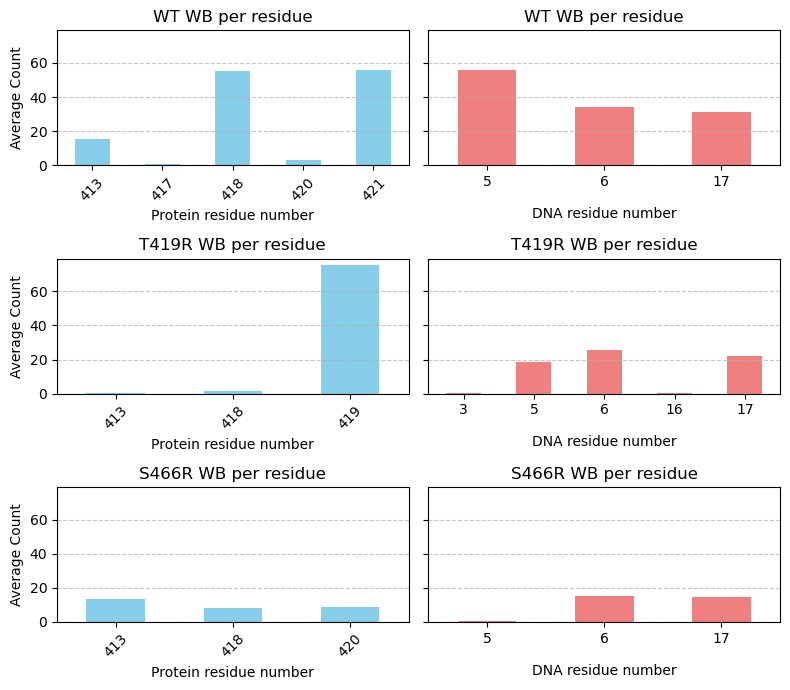

In [13]:
datasets = [
    {'name': 'WT', 'df': wt_combined_2w, 'dfs': wt_dfs},
    {'name': 'T419R', 'df': T419R_combined_2w, 'dfs': T419R_dfs},
    {'name': 'S466R', 'df': S466R_combined_2w, 'dfs': S466R_dfs}
]

fig, axes = plt.subplots(3, 2, figsize=(8, 7), sharey=True)
axes = axes.flatten()


for i, dataset in enumerate(datasets):
    name = dataset['name']
    combined_df = dataset['df']
    dfs = dataset['dfs']
    
    # Filter data to exclude WAT
    sele1_filtered = combined_df[combined_df['sele1_resnm'] != 'WAT']
    sele2_filtered = combined_df[combined_df['sele2_resnm'] != 'WAT']
    
    # Print number of excluded rows
    print(f"Rows excluded from sele1_filtered ({name}):", len(combined_df) - len(sele1_filtered))
    print(f"Rows excluded from sele2_filtered ({name}):", len(combined_df) - len(sele2_filtered))
    
    # Count entries per resid and average
    sele1_counts = sele1_filtered['sele1_resid_adj'].value_counts().sort_index() / len(dfs)
    sele2_counts = sele2_filtered['sele2_resid_adj'].value_counts().sort_index() / len(dfs)
    
    # Print sums
    print(f"Sum of sele1_counts {name}:", sele1_counts.sum())
    print(f"Sum of sele2_counts {name}:", sele2_counts.sum())
    print(f"Raw sele1_counts {name}:", sele1_filtered['sele1_resid_adj'].value_counts().sort_index().sum())
    print(f"Raw sele2_counts {name}:", sele2_filtered['sele2_resid_adj'].value_counts().sort_index().sum())
    
    # Plot sele1_resid_adj (protein) on left subplot (axes[i*2])
    ax1 = axes[i * 2]
    sele1_counts.plot(kind='bar', color='skyblue', ax=ax1)
    ax1.set_xlabel('Protein residue number')
    ax1.set_ylabel('Average Count')
    ax1.set_title(f'{name} WB per residue')
    ax1.grid(axis='y', linestyle='--', alpha=0.7)
    ax1.tick_params(axis='x', rotation=45)
    
    # Plot sele2_resid_adj (DNA) on right subplot (axes[i*2 + 1])
    ax2 = axes[i * 2 + 1]
    sele2_counts.plot(kind='bar', color='lightcoral', ax=ax2)
    ax2.set_xlabel('DNA residue number', labelpad=13)
    ax2.set_title(f'{name} WB per residue')
    ax2.grid(axis='y', linestyle='--', alpha=0.7)
    ax2.tick_params(axis='x', rotation=0)


plt.tight_layout()
plt.show()